In [9]:
%matplotlib widget
from matplotlib import pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.signal import peak_widths
import numpy as np
import os
import importlib
from sklearn.metrics import mean_squared_error
from PIL import Image


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import P_and_P_func
importlib.reload(P_and_P_func)
from P_and_P_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import PaP_plotting_func
importlib.reload(PaP_plotting_func)
from PaP_plotting_func import *




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolation_func_VF import *
import AR_interpolation_func_VF
importlib.reload(AR_interpolation_func_VF)
from AR_interpolation_func_VF  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolations_plotting_VF import *
import AR_interpolations_plotting_VF
importlib.reload(AR_interpolations_plotting_VF)
from AR_interpolations_plotting_VF  import *




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import SMS_map
importlib.reload(SMS_map)
from SMS_map import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import DTT_func
importlib.reload(DTT_func)
from DTT_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
from FWHM_treatment_func import *
import FWHM_treatment_func
importlib.reload(FWHM_treatment_func)
from FWHM_treatment_func  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_plot
importlib.reload(PaP_quantitative_study_plot)
from PaP_quantitative_study_plot import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_func
importlib.reload(PaP_quantitative_study_func)
from PaP_quantitative_study_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Linear_spectra_meas')
from Spectra_computation_func import *
import Spectra_computation_func
importlib.reload(Spectra_computation_func)
from Spectra_computation_func  import *

from Spectra_plotting import *
import Spectra_plotting
importlib.reload(Spectra_plotting)
from Spectra_plotting  import *


import matplotlib.image
import matplotlib.lines as mlines
import matplotlib.patches as mpatches

import matplotlib.animation as animation


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Illustrations')
import gif_func
importlib.reload(gif_func)
from gif_func import *



import matplotlib as mpl
mpl.rcParams["font.size"] = 18

dir_save_data = r'C:\Users\nberr\PhD\Conference\Son et lumière 2025\Poster\Figures'

## Plot linear spectra of ND

### Spectre pour l'introduction sur la SMS

In [2]:
### Get calib

dir_calib = r'H:\commun\Utilisateur FNO\Nathan\Experimental\Calibration\Nanoscope 2\March 2025\ND4-1-col2\Calib_finale'

Source_list = ['OPO', 'SHG']
FWHM_data = get_FWHM_data(dir_calib, Source_list)
WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_2D_mean']


#Get spectra
delta_y = 300e-9

Spectra_Data = {}

dir_root1 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Silice thick 4,5 - D1 zone1' 

Spectra_Data['ND'] = Spectra_computation(dir_root1, 'Linear spectra', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '01-Jul-2025-Spectre_theta_170', force_recomputation=False, spectra_title = '31-Mar-2025_Spectre_theta_0', method='fine')

data = Spectra_Data['ND']


## Plot spectra

#fit data
Res_fit = Lorentz_fit_energy_spectra(data)



Linear spectra already treated


C:\Users\nberr\AppData\Local\Temp\ipykernel_18992\1231704727.py:43: RuntimeWarning:

divide by zero encountered in divide



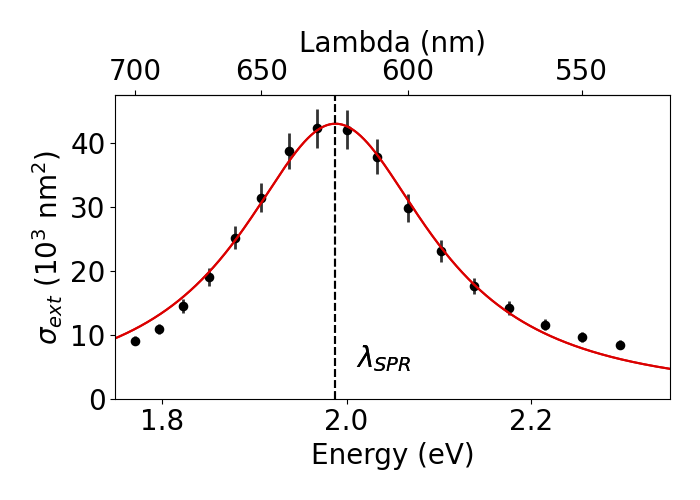

In [3]:
mpl.rcParams["font.size"] = 20
fig, ax = plt.subplots(figsize=(7,5))    




L1 = [data['Lambda'][kkey] for kkey in data['Lambda']]
All_lambda = np.concatenate(L1)
E_min = 1240/((np.max(All_lambda)*1e9))-0.1
E_max = 1240/(np.min(All_lambda)*1e9)+0.1



E = np.linspace(E_min, E_max, 1000)


idx_begin = -2
idx_end = 3
for source_key in data['Source_list'] :

    plt.scatter(1240/(data['Lambda'][source_key][idx_end:idx_begin]*1e9), data['Sigma'][source_key][idx_end:idx_begin]*1e15,s = 35,color='black', label=source_key)
    plt.errorbar(1240/(data['Lambda'][source_key][idx_end:idx_begin]*1e9), data['Sigma'][source_key][idx_end:idx_begin]*1e15, yerr = data['Sigma_err'][source_key][idx_end:idx_begin]*1e15, linestyle='',alpha=0.8, linewidth=2,color='black')

    plt.plot(E, Lorentz_no_offset(E, Res_fit['E_c'], Res_fit['w'], Res_fit['A'])*1e15, color="#DB0000")
    plt.axvline(E[np.argmax(Lorentz_no_offset(E, Res_fit['E_c'], Res_fit['w'], Res_fit['A']))], color='black', linestyle='--')
    plt.text(2.01, 5, r'$\lambda_{SPR}$')

#ax.text(0.45, 0.1, r'$\lambda_\mathrm{SPR}$ = 640 nm', fontsize=15,  transform=ax.transAxes)
#plt.axvline(1240/640, linestyle='--',alpha=0.5, color='black')


plt.ylim(bottom = 0)



plt.xlim((1.75, 2.35))
plt.ylabel(r"$\sigma_{ext}$ ($10^3$ nm$^2$)")
plt.xlabel('Energy (eV)')



def convert(x) :
    return 1240/x

ax2 = ax.secondary_xaxis("top", functions=(convert, convert))

ax2.set_xlabel("Lambda (nm)")
#plt.grid('on')
plt.subplots_adjust(top=0.7)
#plt.title(data['title'])
#plt.legend()
plt.tight_layout()
fig.patch.set_facecolor( '#FF000000' )
os.chdir(dir_save_data)

plt.savefig('ND Spectra for SMS part.svg')


In [32]:
dir_calib = r'H:\commun\Utilisateur FNO\Nathan\Experimental\Calibration\Nanoscope 2\March 2025\ND4-1-col2\Calib_finale'

Source_list = ['OPO', 'SHG']
FWHM_data = get_FWHM_data(dir_calib, Source_list)
WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_2D_mean']


Get the Plot info data

In [33]:
Plot_info = {}
Plot_info['fontsize'] = 25



Plot_info['Markers'] = {}
Plot_info['Markers']['SHG'] = 'v'
Plot_info['Markers']['OPO'] = '.'
Plot_info['Markers']['CHA'] = '*'
Plot_info['Markers']['Maitai'] = '*'

Plot_info['Couleurs'] = {}
Plot_info['Couleurs']['SHG'] = ["#004b6b", '#9dc6e0']
Plot_info['Couleurs']['OPO'] = ['#488f31', '#b6ccab']
Plot_info['Couleurs']['CHA'] = ['#de425b', '#efb7b8']
Plot_info['Couleurs']['Maitai'] = ['#de425b', '#efb7b8']

Col='#488f31'

In [34]:
delta_y = 300e-9

Spectra_Data = {}

dir_root1 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice - thick\AR 4,5\zone-1' 

Spectra_Data['ND'] = Spectra_computation(dir_root1, 'D1', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '31-Mar-2025_Spectre_theta_0', force_recomputation=False, spectra_title = '31-Mar-2025_Spectre_theta_0', method='fine')

data = Spectra_Data['ND']

D1 already treated


Big size spectra figure

C:\Users\nberr\AppData\Local\Temp\ipykernel_9940\3812729824.py:27: RuntimeWarning:

divide by zero encountered in divide



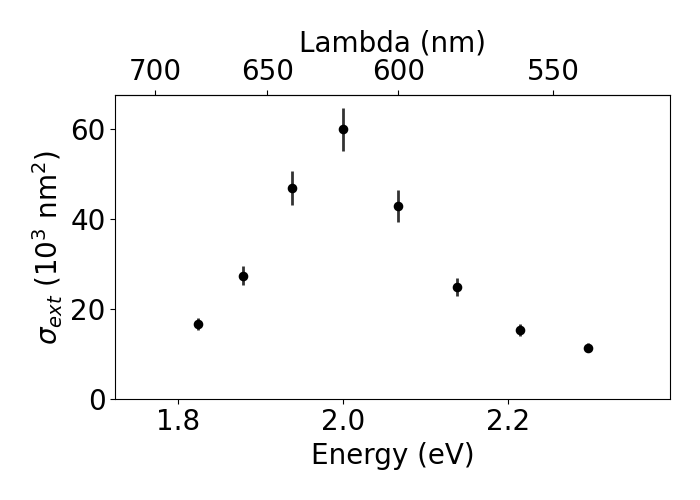

In [35]:
mpl.rcParams["font.size"] = 20
fig, ax = plt.subplots(figsize=(7,5))    

for source_key in data['Source_list'] :

    plt.scatter(1240/(data['Lambda'][source_key]*1e9), data['Sigma'][source_key]*1e15,s = 35,color='black', label=source_key)
    plt.errorbar(1240/(data['Lambda'][source_key]*1e9), data['Sigma'][source_key]*1e15, yerr = data['Sigma_err'][source_key]*1e15, linestyle='',alpha=0.8, linewidth=2,color='black')

#ax.text(0.45, 0.1, r'$\lambda_\mathrm{SPR}$ = 640 nm', fontsize=15,  transform=ax.transAxes)
#plt.axvline(1240/640, linestyle='--',alpha=0.5, color='black')


plt.ylim(bottom = 0)

L1 = [data['Lambda'][kkey] for kkey in data['Lambda']]
All_lambda = np.concatenate(L1)
E_min = 1240/((np.max(All_lambda)*1e9))-0.1
E_max = 1240/(np.min(All_lambda)*1e9)+0.1

plt.xlim((E_min, E_max))
plt.ylabel(r"$\sigma_{ext}$ ($10^3$ nm$^2$)")
plt.xlabel('Energy (eV)')



def convert(x) :
    return 1240/x

ax2 = ax.secondary_xaxis("top", functions=(convert, convert))

ax2.set_xlabel("Lambda (nm)")
#plt.grid('on')
plt.subplots_adjust(top=0.7)
#plt.title(data['title'])
#plt.legend()
plt.tight_layout()
fig.patch.set_facecolor( '#FF000000' )
os.chdir(dir_save_data)

plt.savefig('ND Spectra.svg')


### Q-factor ND PaP signal

In [51]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice - thick\AR 4,5\zone-1\D1'
#dir_name = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'
dir_name = r'31-Mar-2025_PaP_Pp6uW_ldap410nm_ldas650nm'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'


dir_save_treated_data = dir_root + '\\' + dir_name


Trace = get_PaP_dataset(dir_root + '\\' + dir_name, filename)

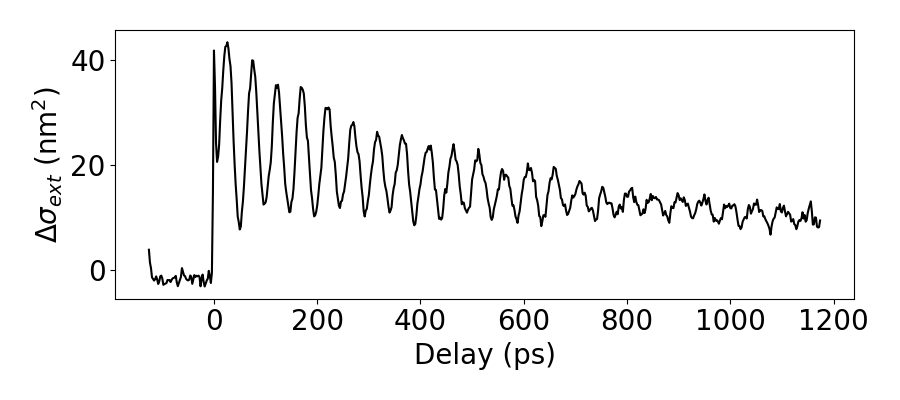

In [58]:
#alpha_DTT_dsigma = -178029.6157014482 #conversion coefficient from DTT to delta sigma in nm2
alpha_DTT_dsigma = -172035.5417065772 #conversion coefficient from DTT to delta sigma in nm2

mpl.rcParams["font.size"] = 20
fig, ax = plt.subplots(figsize = (9,4))

#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax.plot(Trace.delay_tot, Trace.DTT_tot*alpha_DTT_dsigma,  color = 'black')


ax.set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)')
ax.set_xlabel('Delay (ps)')
#ax.grid('on')
fig.patch.set_facecolor( '#FF000000' )
plt.tight_layout()


os.chdir(dir_save_data)

plt.savefig('PaP total signal on quartz.svg')

C:\Users\nberr\AppData\Local\Temp\ipykernel_19240\3329557436.py:11: UserWarning:

linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "r-" (-> linestyle='-'). The keyword argument will take precedence.

C:\Users\nberr\AppData\Local\Temp\ipykernel_19240\3329557436.py:11: UserWarning:

color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.



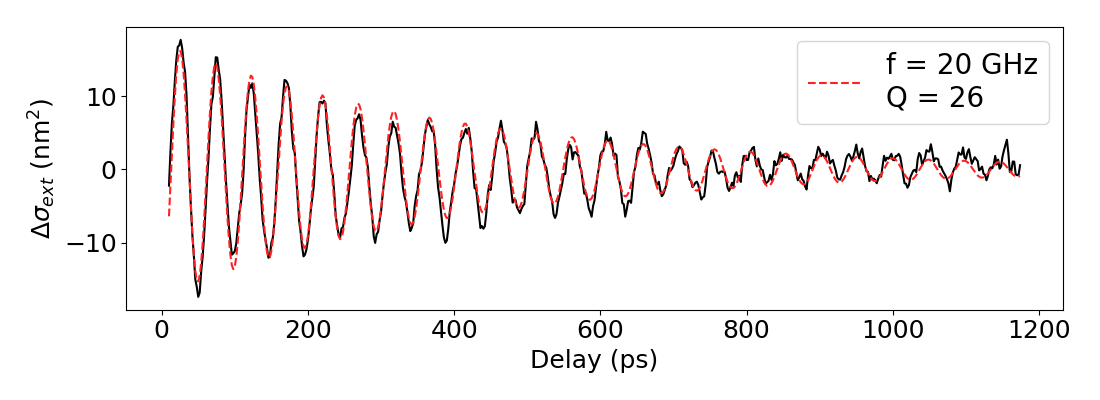

In [10]:
#alpha_DTT_dsigma = -178029.6157014482 #conversion coefficient from DTT to delta sigma in nm2
alpha_DTT_dsigma = -172035.5417065772 #conversion coefficient from DTT to delta sigma in nm2


fig, ax = plt.subplots(figsize = (11,4))

#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax.plot(Trace.delay, Trace.DTT_acoustic*alpha_DTT_dsigma,  color = 'black')


ax.plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label=r'f = 20 GHz' +  "\n" + 'Q = 26')



ax.set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)')
ax.set_xlabel('Delay (ps)')
#ax.grid('on')
fig.patch.set_facecolor( '#FF000000' )
plt.legend(fontsize=20)
plt.tight_layout()


os.chdir(dir_save_data)

plt.savefig('PaP acoustic signal on quartz.svg')

## Quality factor study

big version

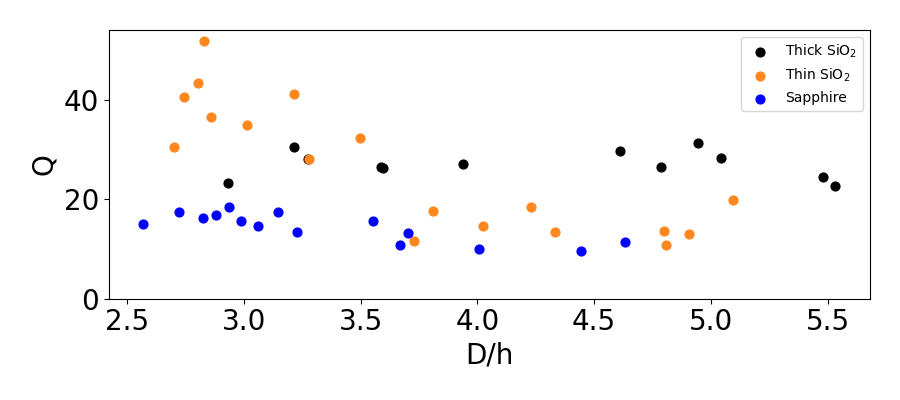

In [11]:
mpl.rcParams["font.size"] = 20

fname='Treated_data'


Data = {}
Color_dic = {}
dir_1 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice - thick\AR_estimation\ND_measurements_AR_treated'
data_name_1 = r'Thick SiO$_2$'
Data[data_name_1] = get_treated_AR_data(dir_1, fname)
Color_dic[data_name_1] = 'black'


dir_3 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice - membrane\AR_estimation\ND_measurements_AR_treated'
data_name_3 = r'Thin SiO$_2$'
Data[data_name_3] = get_treated_AR_data(dir_3, fname)
Color_dic[data_name_3] = "#FF871E"

dir_2 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Sapphire\AR_estimation\ND_measurements_AR_treated'
data_name_2 = 'Sapphire'
Data[data_name_2] = get_treated_AR_data(dir_2, fname)
Color_dic[data_name_2] = 'blue'

## Make the plot
fig, ax = plt.subplots(figsize = (9,4))
for key in Data :
        data = Data[key]




        compt=0
        for kkey in data :
            spectra = data[kkey]

            if spectra['Q'] != 0 :
                if compt==0 :
                    ax.scatter(spectra['1D_Area']['D']/21, spectra['Q'], c = Color_dic[key], label=key, s=40)
                else :
                    ax.scatter(spectra['1D_Area']['D']/21, spectra['Q'], c = Color_dic[key], s=40)

                #ax.errorbar(spectra['1D_estimation_Aire_SPR']['AR'], spectra['Q'], yerr = spectra['Q_err'], color=Color_dic[key])
            compt+=1

ax.set_xlabel('D/h')
ax.set_ylabel('Q')
#ax.grid()


        # os.chdir(r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Quartz')

        # plt.savefig('test.png')
        # plt.savefig('test.pdf')

ax.set_ylim(bottom = 0)
plt.legend(fontsize = 10)
plt.tight_layout()
plt.show()
fig.patch.set_facecolor( '#FF000000' )
os.chdir(dir_save_data)

plt.savefig('Q_factor_study_big.svg')


small version

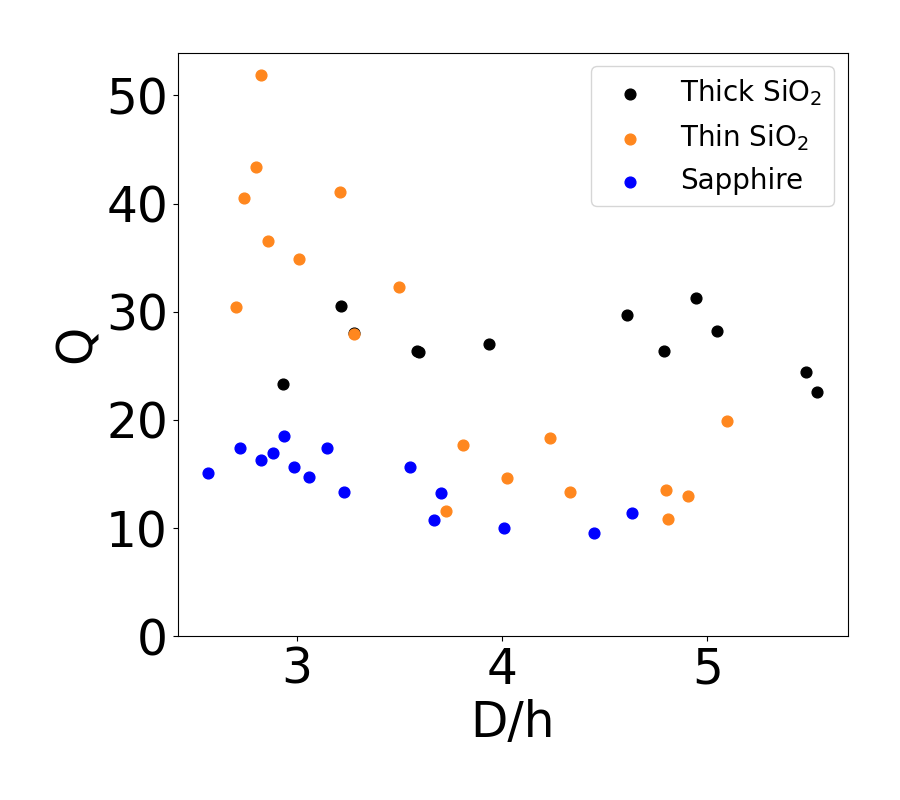

In [13]:
mpl.rcParams["font.size"] = 35

fname='Treated_data'


Data = {}
Color_dic = {}
dir_1 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice - thick\AR_estimation\ND_measurements_AR_treated'
data_name_1 = r'Thick SiO$_2$'
Data[data_name_1] = get_treated_AR_data(dir_1, fname)
Color_dic[data_name_1] = 'black'


dir_3 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice - membrane\AR_estimation\ND_measurements_AR_treated'
data_name_3 = r'Thin SiO$_2$'
Data[data_name_3] = get_treated_AR_data(dir_3, fname)
Color_dic[data_name_3] = "#FF871E"

dir_2 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Sapphire\AR_estimation\ND_measurements_AR_treated'
data_name_2 = 'Sapphire'
Data[data_name_2] = get_treated_AR_data(dir_2, fname)
Color_dic[data_name_2] = 'blue'

## Make the plot
fig, ax = plt.subplots(figsize = (9,8))
for key in Data :
        data = Data[key]




        compt=0
        for kkey in data :
            spectra = data[kkey]

            if spectra['Q'] != 0 :
                if compt==0 :
                    ax.scatter(spectra['1D_Area']['D']/21, spectra['Q'], c = Color_dic[key], label=key, s=60)
                else :
                    ax.scatter(spectra['1D_Area']['D']/21, spectra['Q'], c = Color_dic[key], s=60)

                #ax.errorbar(spectra['1D_estimation_Aire_SPR']['AR'], spectra['Q'], yerr = spectra['Q_err'], color=Color_dic[key])
            compt+=1

ax.set_xlabel('D/h')
ax.set_ylabel('Q')
#ax.grid()


        # os.chdir(r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Quartz')

        # plt.savefig('test.png')
        # plt.savefig('test.pdf')

ax.set_ylim(bottom = 0)
plt.legend(fontsize = 20)
plt.tight_layout()
plt.show()

os.chdir(dir_save_data)
fig.patch.set_facecolor( '#FF000000' )
plt.savefig('Q_factor_study_small.svg')

### 2 PaP signal for same ND geometry

### Compoisition effect : NDb zone-Sylvie (Sapphire) / ND7 zone 1 (Silice thick)

In [9]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Sapphire\AR2.3\zone1\NDb'
#dir_name = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'
dir_name = r'02-Dec-2024_PaP_Pp6uW_ldap410nm_ldas630nm'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'





Trace_NDb = get_PaP_dataset(dir_root + '\\' + dir_name, filename)


dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice - thick\AR 4,5\zone-1\D7'
#dir_name = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'
dir_name = r'04-Apr-2025_PaP_Pp6uW_ldap410nm_ldas650nm'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'



Trace_ND7 = get_PaP_dataset(dir_root + '\\' + dir_name, filename)




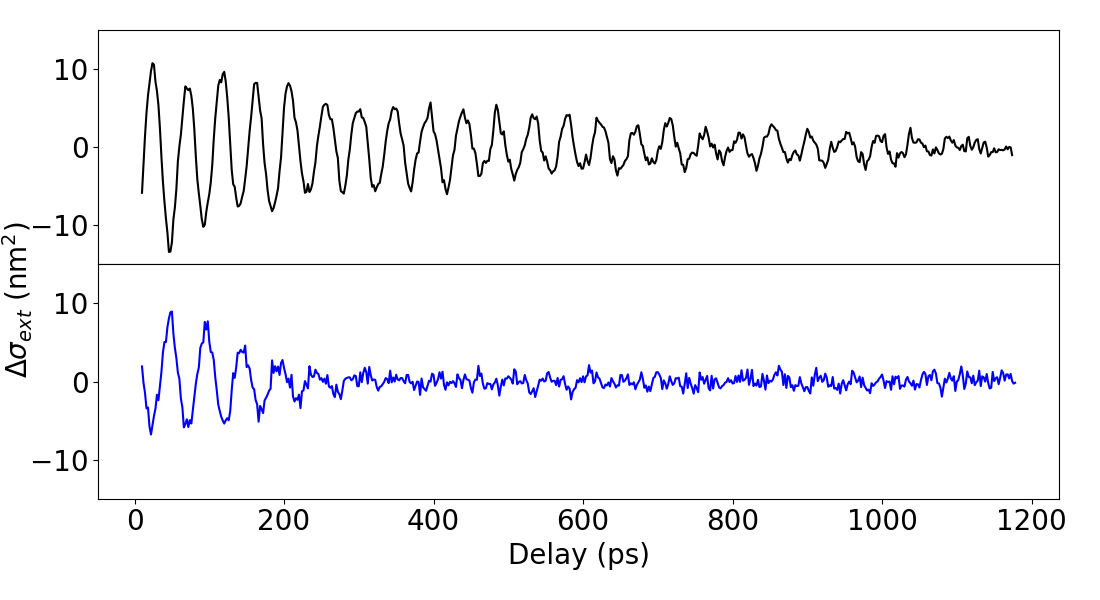

In [15]:
coeff_NDb = -169173.92653200435 #conversion coefficient from DTT to delta sigma in nm2
coeff_ND7 = -172035.5417065772


mpl.rcParams["font.size"] = 20
fig,ax = plt.subplots(figsize=(11, 6),nrows=2, sharex=True)
# set height ratios for subplots





#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax[0].plot(Trace_ND7.delay, Trace_ND7.DTT_acoustic*coeff_ND7,  color = 'black')
#ax[0].plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label=r'f = 20 GHz' +  "\n" + 'Q = 26')


ax[1].plot(Trace_NDb.delay, Trace_NDb.DTT_acoustic*coeff_NDb,  color = 'blue')


ax[1].set_ylim((-15, 15))
ax[0].set_ylim((-15, 15))

ax[1].set_xlabel('Delay (ps)')
plt.tight_layout()
fig.text(0, 0.5, r'$\Delta \sigma_{ext}$ (nm$^2$)', va='center', rotation='vertical')


plt.subplots_adjust(hspace=.0)
#ax[1].plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label=r'f = 20 GHz' +  "\n" + 'Q = 26')


os.chdir(dir_save_data)
fig.patch.set_facecolor( '#FF000000' )
plt.savefig('2 PaP signals - composition effect.svg')




### Geometry effect : ND6 AR4.5 (Silice thin) / D5 zone 1 (Silice thick)

In [14]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice - membrane\AR4.5gridA5\AR4.5-6\20231219_pr600nm_pp410nm_Ppp=3uw_pol-12'
dir_name = r'Traces'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'





Trace_ND6 = get_PaP_dataset(dir_root + '\\' + dir_name, filename)


dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice - thick\AR 4,5\zone-1\D5'
#dir_name = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'
dir_name = r'03-Apr-2025_PaP_Pp6uW_ldap410nm_ldas650nm'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'



Trace_ND5 = get_PaP_dataset(dir_root + '\\' + dir_name, filename)

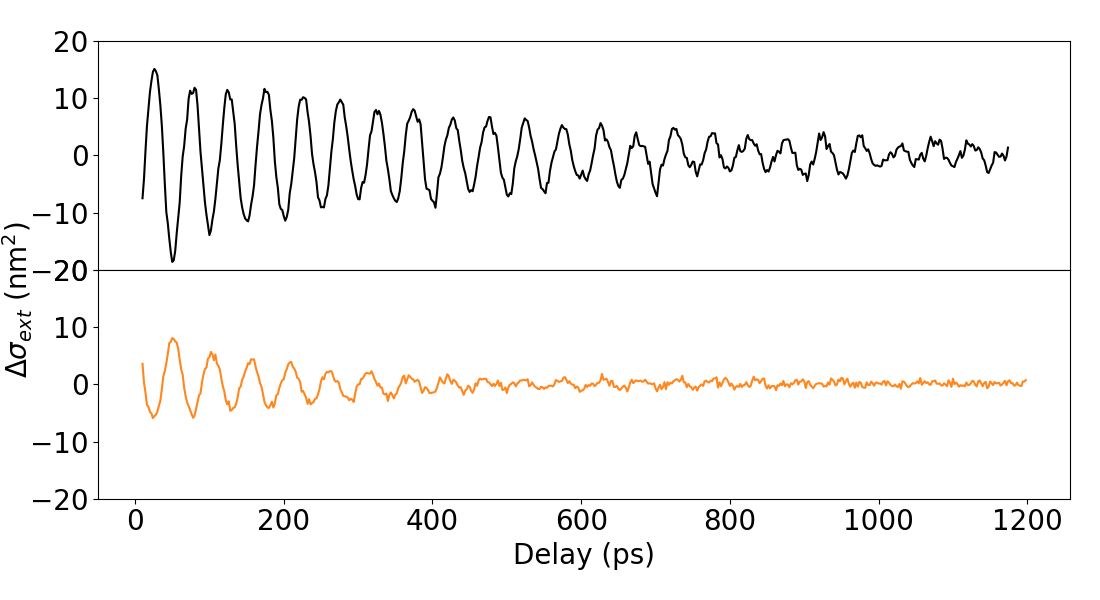

In [16]:
coeff_ND6 = -154624.64077338015 #conversion coefficient from DTT to delta sigma in nm2
coeff_ND5 = -172035.5417065772


mpl.rcParams["font.size"] = 20
fig,ax = plt.subplots(figsize=(11, 6),nrows=2, sharex=True)
# set height ratios for subplots





#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax[0].plot(Trace_ND5.delay, Trace_ND5.DTT_acoustic*coeff_ND5,  color = 'black')
#ax[0].plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label=r'f = 20 GHz' +  "\n" + 'Q = 26')


ax[1].plot(Trace_ND6.delay[:np.argwhere(Trace_ND6.delay>=1200).min()], Trace_ND6.DTT_acoustic[:np.argwhere(Trace_ND6.delay>=1200).min()]*coeff_ND6,  color = "#FF871E")


ax[1].set_ylim((-20, 20))
ax[0].set_ylim((-20, 20))

ax[1].set_xlabel('Delay (ps)')
plt.tight_layout()
fig.text(0, 0.5, r'$\Delta \sigma_{ext}$ (nm$^2$)', va='center', rotation='vertical')


plt.subplots_adjust(hspace=.0)
#ax[1].plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label=r'f = 20 GHz' +  "\n" + 'Q = 26')


os.chdir(dir_save_data)
fig.patch.set_facecolor( '#FF000000' )
plt.savefig('2 PaP signals - geometry effect.svg')


## Illustration of ensemble measurements

C:\Users\nberr\AppData\Local\Temp\ipykernel_8656\4020373611.py:28: RuntimeWarning:

overflow encountered in divide



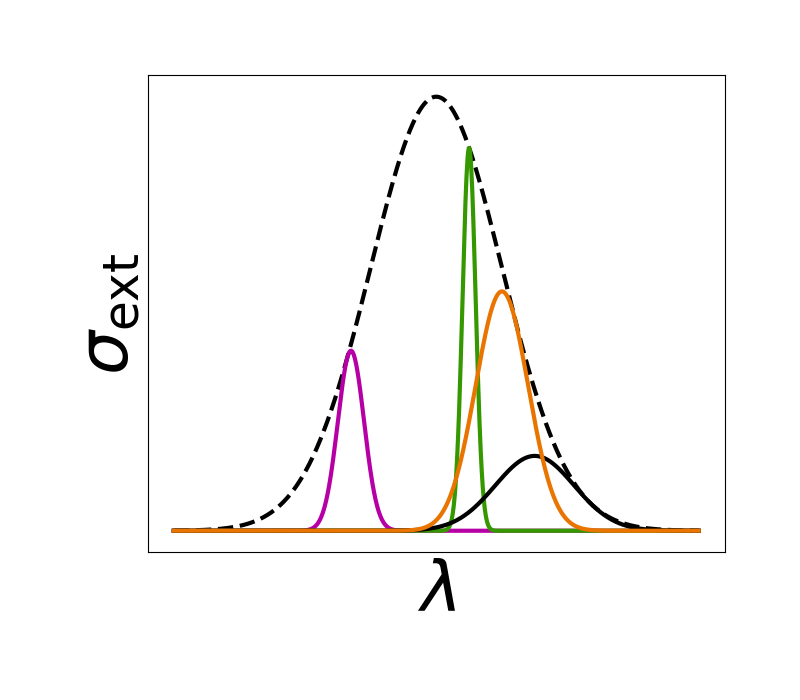

In [13]:
mpl.rcParams["font.size"] = 50
fig, ax = plt.subplots(figsize=(8,7))

# Paramètres de l'enveloppe
mu_env = 0
sigma_env = 1.0
x = np.linspace(-4, 4, 1000)
gauss_env = np.exp(- (x - mu_env)**2 / (2 * sigma_env**2))

# Tracer l'enveloppe noire en pointillés
ax.plot(x, gauss_env, 'k--', label='Enveloppe gaussienne (σ=1)', linewidth=3)

# Paramètres des gaussiennes internes (plus étroites, décentrées)
sigmas = [0.2, 0.1, 0.6, 0.4]
centers = [-1.3, 0.5, 1.5, 1]
colors = ["#B600A6", "#359800", "#000000", "#E97400"]



ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks

for mu, sigma, c in zip(centers, sigmas, colors):
    gauss = np.exp(- (x - mu)**2 / (2 * sigma**2))
    
    # Calcul du facteur de normalisation pour garantir que la courbe est toujours sous l'enveloppe
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = gauss_env / gauss
        ratio = np.where(gauss > 0, ratio, np.inf)  # éviter divisions par zéro
        scale = np.min(ratio)

    gauss_scaled = scale * gauss
    ax.plot(x, gauss_scaled, c = c, label=f'σ={sigma:.2f}, µ={mu:.1f}', linewidth=3)

# Mise en forme

plt.xlabel(r'$\lambda$')
plt.ylabel(r'$\sigma_\mathrm{ext}$')
plt.tight_layout()
fig.patch.set_facecolor( '#FF000000' )
plt.show()


os.chdir(dir_save_data)

plt.savefig('Ensemble study plot.svg')

mpl.rcParams["font.size"] = 18

## Intro : nanosensors

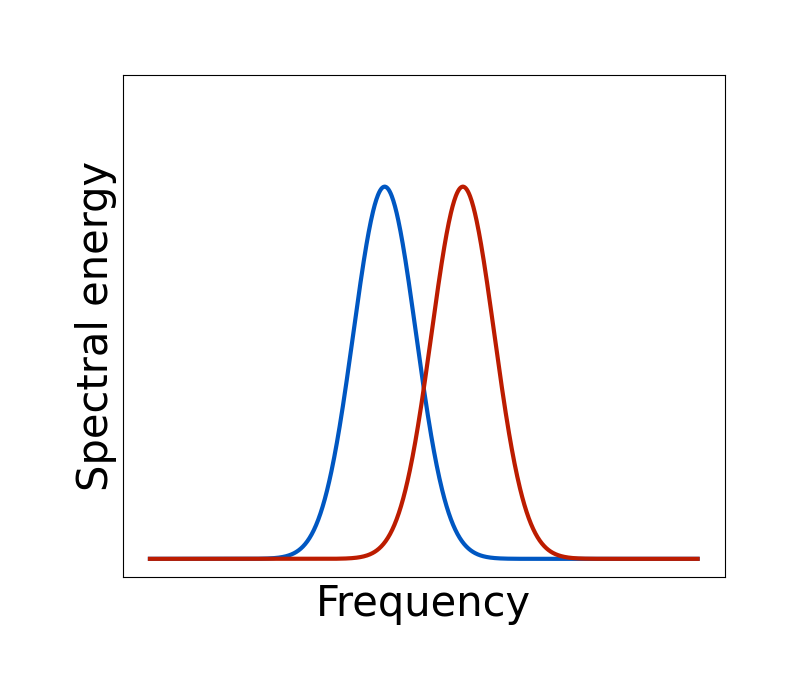

In [3]:
mpl.rcParams["font.size"] = 50
fig, ax = plt.subplots(figsize=(8,7))



# Paramètres de l'enveloppe
mu_env = 0
sigma_env = 1.0
x = np.linspace(-1.5, 2, 1000)
gauss_env = np.exp(- (x - mu_env)**2 / (2 * sigma_env**2))


# Paramètres des gaussiennes internes (plus étroites, décentrées)
sigmas = [0.2, 0.2]
centers = [0, 0.5, 1.5, 1]
colors = ["#0057C2", "#BC1C00"]



ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks

for mu, sigma, c in zip(centers, sigmas, colors):
    gauss = np.exp(- (x - mu)**2 / (2 * sigma**2))
    
   
    ax.plot(x, gauss, c = c, label=f'σ={sigma:.2f}, µ={mu:.1f}', linewidth=3)

# Mise en forme

plt.xlabel(r'Frequency', fontsize=30)
plt.ylabel(r'Spectral energy', fontsize=30)
plt.ylim(top=1.3)
plt.tight_layout()
fig.patch.set_facecolor( '#FF000000' )
plt.show()


os.chdir(dir_save_data)

plt.savefig('Intro nanosensors.svg')

mpl.rcParams["font.size"] = 18

## Plot a PaP signal

In [17]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3\PaP_study'

dir_name = r'6-Fev-2025_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_610'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'
Trace = get_PaP_dataset(dir_root + '\\' + dir_name, filename)

dir_root2 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3\PaP_study'

dir_name2 = r'22-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_640'
dir_name2 += '_treated'
filename2 = 'Trace_acoustic_fitted'
Trace2 = get_PaP_dataset(dir_root2 + '\\' + dir_name2, filename2)

dir_root3 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3\PaP_study'
#dir_name = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'
dir_name3 = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'
dir_name3 += '_treated'
filename3 = 'Trace_acoustic_fitted'
Trace3 = get_PaP_dataset(dir_root3 + '\\' + dir_name3, filename3)

dir_root4 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3\PaP_study'
#dir_name = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'
dir_name4 = r'21-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_660'
dir_name4 += '_treated'
filename4 = 'Trace_acoustic_fitted'
Trace4 = get_PaP_dataset(dir_root4 + '\\' + dir_name4, filename3)

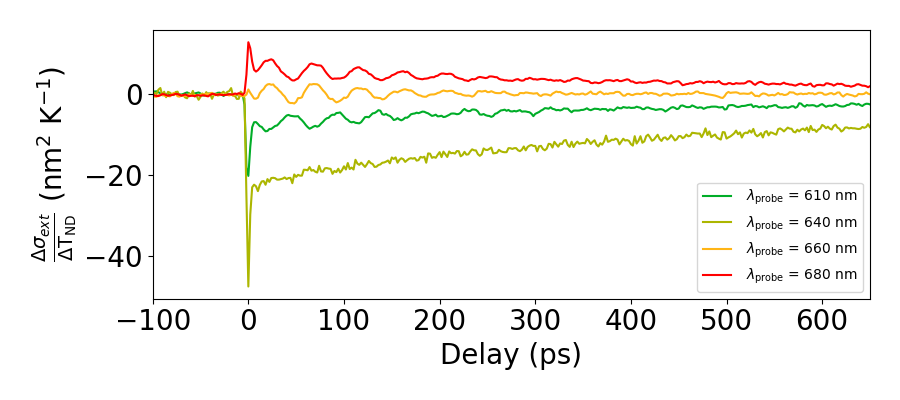

In [20]:
alpha_1 = -162005.04502 #conversion coefficient from DTT to delta sigma in nm2
alpha_2 = -173700.41189
alpha_3 = -182602.07738
alpha_4 = -178029.6157


dT1 = 2.95879 #650nm and less
dT2 = 4.73479 #660 nm and more
fig, ax = plt.subplots(figsize = (9,4))

#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax.plot(Trace.delay_tot, Trace.DTT_tot*alpha_1/dT1,  color = "#00AD28", label=r' $\lambda_\mathrm{probe}$ = 610 nm')
ax.set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)')

#ax.grid('on')

ax.plot(Trace2.delay_tot[:400], Trace2.DTT_tot[:400]*alpha_2/dT1,  color = "#ACB600", label = r' $\lambda_\mathrm{probe}$ = 640 nm')




ax.plot(Trace4.delay_tot, Trace4.DTT_tot*alpha_3/dT2,  color = "#FFB516", label = r' $\lambda_\mathrm{probe}$ = 660 nm')



ax.plot(Trace3.delay_tot, Trace3.DTT_tot*alpha_4/dT2,  color = "#FF0000", label=r' $\lambda_\mathrm{probe}$ = 680 nm')
ax.set_ylabel(r'$\frac{\Delta \sigma_{ext}}{\Delta \mathrm{T_{ND}}}$ (nm$^2$ K$^{-1}$)')
ax.set_xlabel('Delay (ps)')


plt.xlim(left=-100, right=650)
plt.legend(fontsize=10)
fig.patch.set_facecolor( '#FF000000' )


plt.tight_layout()


os.chdir(dir_save_data)

plt.savefig('PaP signal 4 wavelengths.svg')

## Thermal and Acoustic sensitivity

## Linear spectra of ND

## Plot Spectra of Sapphire ND

In [2]:
Plot_info = {}
Plot_info['fontsize'] = 25



Plot_info['Markers'] = {}
Plot_info['Markers']['SHG'] = 'v'
Plot_info['Markers']['OPO'] = '.'
Plot_info['Markers']['CHA'] = '*'
Plot_info['Markers']['Maitai'] = '*'

Plot_info['Couleurs'] = {}
Plot_info['Couleurs']['SHG'] = ["#004b6b", '#9dc6e0']
Plot_info['Couleurs']['OPO'] = ['#488f31', '#b6ccab']
Plot_info['Couleurs']['CHA'] = ['#de425b', '#efb7b8']
Plot_info['Couleurs']['Maitai'] = ['#de425b', '#efb7b8']

Col='#488f31'

In [3]:
## Calibration data

dir_calib = r'H:\commun\Utilisateur FNO\Nathan\Experimental\Calibration\Nanoscope 2\March 2025\ND4-1-col2\Calib_finale'

Source_list = ['OPO', 'SHG']
FWHM_data = get_FWHM_data(dir_calib, Source_list)
WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_2D_mean']




# Spectra data
delta_y = 300e-9

Spectra_Data = {}

dir_root1 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3' 

Spectra_Data['ND'] = Spectra_computation(dir_root1, 'Linear spectra', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '21-Jan-2025-Spectre_theta_90', force_recomputation=False, spectra_title = '21-Jan-2025-Spectre_theta_90', method='fine')

data = Spectra_Data['ND']

Linear spectra already treated


Big size spectra figure

C:\Users\nberr\AppData\Local\Temp\ipykernel_13316\2300353693.py:26: RuntimeWarning:

divide by zero encountered in divide



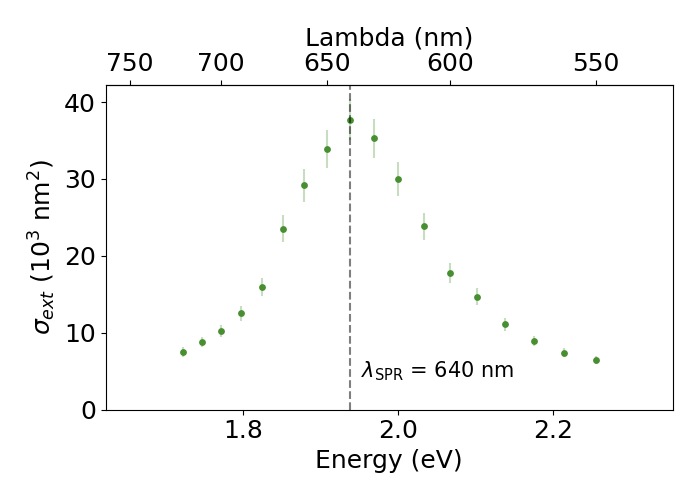

In [4]:
fig, ax = plt.subplots(figsize=(7,5))    

for source_key in data['Source_list'] :

    plt.scatter(1240/(data['Lambda'][source_key]*1e9), data['Sigma'][source_key]*1e15,s = 15,color=Col, label=source_key)
    plt.errorbar(1240/(data['Lambda'][source_key]*1e9), data['Sigma'][source_key]*1e15, yerr = data['Sigma_err'][source_key]*1e15, linestyle='',alpha=0.3, color=Col)

ax.text(0.45, 0.1, r'$\lambda_\mathrm{SPR}$ = 640 nm', fontsize=15,  transform=ax.transAxes)
plt.axvline(1240/640, linestyle='--',alpha=0.5, color='black')


plt.ylim(bottom = 0)

L1 = [data['Lambda'][kkey] for kkey in data['Lambda']]
All_lambda = np.concatenate(L1)
E_min = 1240/((np.max(All_lambda)*1e9))-0.1
E_max = 1240/(np.min(All_lambda)*1e9)+0.1

plt.xlim((E_min, E_max))
plt.ylabel(r"$\sigma_{ext}$ ($10^3$ nm$^2$)")
plt.xlabel('Energy (eV)')



def convert(x) :
    return 1240/x

ax2 = ax.secondary_xaxis("top", functions=(convert, convert))

ax2.set_xlabel("Lambda (nm)")
#plt.grid('on')
plt.subplots_adjust(top=0.7)
#plt.title(data['title'])
#plt.legend()
plt.tight_layout()

os.chdir(dir_save_data)

plt.savefig('Nd_Sapphire Spectra.svg')


Small size spectra figure

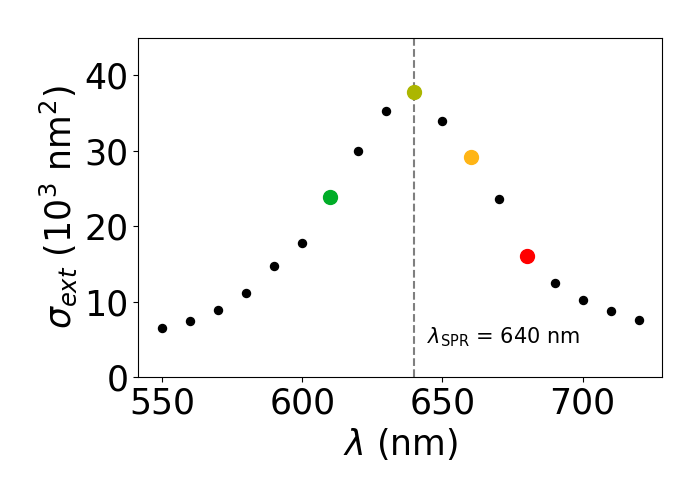

In [18]:
mpl.rcParams["font.size"] = 25

s_size=100

fig, ax = plt.subplots(figsize=(7,5))    

for source_key in data['Source_list'] :

    plt.scatter((data['Lambda'][source_key])*1e9, data['Sigma'][source_key]*1e15,s = s_size/3,color='black', label=source_key, zorder=1)
    

    #plt.errorbar(1240/(data['Lambda'][source_key]*1e9), data['Sigma'][source_key]*1e15, yerr = data['Sigma_err'][source_key]*1e15, linestyle='',alpha=0.3, color=Col)



    for i in range(len(data['Lambda'][source_key])) :
        lda = int(data['Lambda'][source_key][i]*1e9)
        
        if lda == 610 :
            plt.scatter((data['Lambda'][source_key][i])*1e9, data['Sigma'][source_key][i]*1e15,s = s_size,color="#00AD28", label=source_key, zorder=2)
        if lda == 640 :
            plt.scatter((data['Lambda'][source_key][i])*1e9, data['Sigma'][source_key][i]*1e15,s = s_size,color="#ACB600", label=source_key, zorder=2)
        if lda == 660 :
            plt.scatter((data['Lambda'][source_key][i])*1e9, data['Sigma'][source_key][i]*1e15,s = s_size,color="#FFB516", label=source_key, zorder=2)
        if lda == 680 :
            plt.scatter((data['Lambda'][source_key][i])*1e9, data['Sigma'][source_key][i]*1e15,s = s_size,color="#FF0000", label=source_key, zorder=2)


ax.text(0.55, 0.1, r'$\lambda_\mathrm{SPR}$ = 640 nm', fontsize=15,  transform=ax.transAxes)
plt.axvline(640, linestyle='--',alpha=0.5, color='black', zorder=0)


plt.ylim(bottom = 0, top=45)
#plt.xlim((550, 750))
plt.ylabel(r"$\sigma_{ext}$ ($10^3$ nm$^2$)")
plt.xlabel(r'$\lambda$ (nm)')

fig.patch.set_facecolor( '#FF000000' )
ax2.set_xlabel("Lambda (nm)")
#plt.grid('on')
plt.subplots_adjust(top=0.7)
#plt.title(data['title'])
#plt.legend()
plt.tight_layout()

mpl.rcParams["font.size"] = 18

os.chdir(dir_save_data)

plt.savefig('Nd_Sapphire Spectra (small).svg')

## Acoustic and thermic sensitivity

## Gif Acoustique

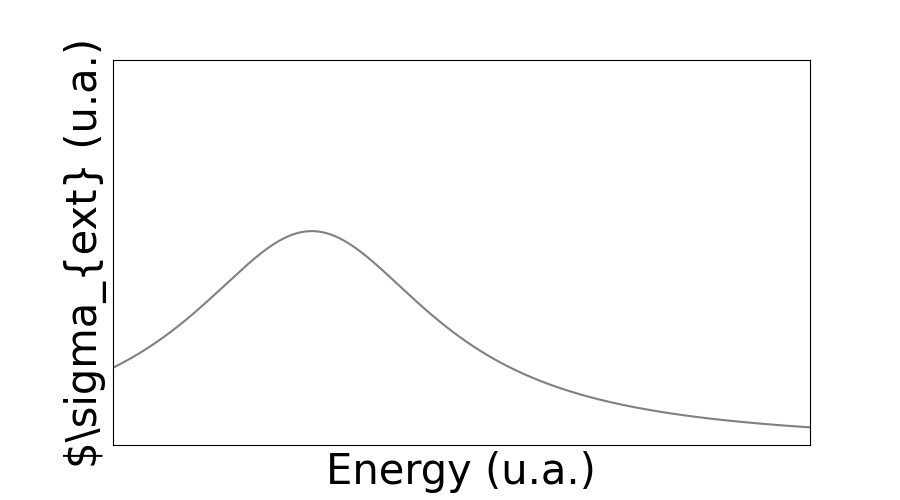

In [6]:
animation_name = 'SPR_acoustic'

mpl.rcParams["font.size"] = 30

fig, ax = plt.subplots(figsize=(9,5))


imax=100

#Set (x,y) limits for axes
xmin_spr, xmax_spr = (1.8,  2.5)

ymin_spr, ymax_spr = (0,  6)


xmin_dtt, xmax_dtt = -350, 1000
ymin_dtt, ymax_dtt = -0.7, 0.7

top_lim = 3
bottom_limit  = -0.5



Energy = np.linspace(1.5, 2.5, 1000)
Time = np.linspace(-300, 1000, imax)

delta_w = 0.05
delta_w = 0
delta_Ec = 0.03

tau = 800/3
T = 100
phi = 0


#Shape variation of the nanosidk
alpha = 0.2 # Dilatation coefficient


#Lorentzian shape for the SPR
A = 1
E_c = 2
w = 0.3
y0=0



ax.set_xlim((xmin_spr, xmax_spr))
ax.set_ylim((ymin_spr, ymax_spr))
ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks
ax.set_xlabel('Energy (u.a.)')
ax.set_ylabel(r'$\sigma_{ext} (u.a.)')




scat = ax.plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='grey')




Colors= list(Color("red").range_to(Color("yellow"),imax))



def animate_lorentz(i) :
    ax.cla()
    #x_probe = Energy[600]


    ### SPR plot 
    ax.set_xlim((xmin_spr, xmax_spr))
    ax.set_ylim((ymin_spr, ymax_spr))
    ax.set_xticks([])  # Remove x-axis ticks
    ax.set_yticks([])  # Remove y-axis ticks
    ax.set_xlabel('Wavelength ')
    ax.set_ylabel(r'$\sigma_{ext}$')

    width, height = 0.2, 0.1
    x_ini, y_ini = 0.15 - width/2, 0.85 - height/2
    x_c, y_c = x_ini - width/2*np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi), y_ini - height/2*np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi)

    rect_disk = mpatches.Rectangle((x_c, y_c), 0.2*(1+ np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi) ), 0.1*(1+np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi)), transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='black')
    ax.add_patch(rect_disk)

    scat = ax.plot(Energy, Lorentz(Energy, E_c+np.array(Time>0)[i]*Osc1(Time[i], delta_Ec, tau, T, phi), w + np.array(Time>0)[i]*Osc1(Time[i], delta_w, tau, T, phi), A, y0),color='blue')
    ax.plot(Energy, Lorentz(Energy, E_c, w , A, y0),color='grey', alpha=0.5)
    #ax.plot([x_probe, x_probe], [Lorentz(x_probe, E_c, w , A, y0), Lorentz(x_probe, E_c+np.array(Time>0)[i]*(Osc1(Time[i], delta_Ec, tau, T, phi)), w + np.array(Time>0)[i]*Osc1(Time[i], delta_w, tau, T, phi), A, y0)], color='green')

   
    #ax.axvline(x_probe, color='green', linestyle='--',zorder=0)
    #ax.text(0.63, 0.8, r'$\lambda_\mathrm{probe}$', color='green',  transform=ax.transAxes)




    return(scat,)

#interval=1000//60
ani = animation.FuncAnimation(fig, animate_lorentz, repeat=True, frames=imax, interval = 10)
plt.show()


os.chdir(dir_save_data)

if  1 :
        
    writer = animation.PillowWriter(fps=15,
                                    metadata=dict(artist='Me'),
                                    bitrate=1800)
    ani.save(animation_name + '.gif', writer=writer)

plt.clf()
mpl.rcParams["font.size"] = 18

## Gif SMS

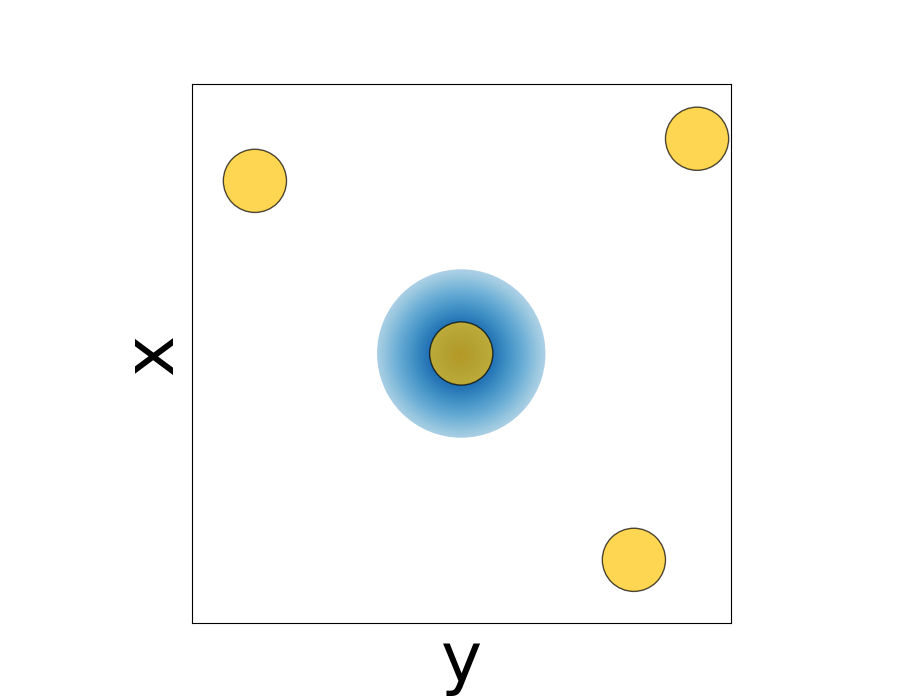

In [6]:
animation_name = 'Animation SMS v2'

mpl.rcParams["font.size"] = 50

fig, ax = plt.subplots(figsize=(9,7))


imax=100

Time = np.linspace(-300, 1000, imax)

#Set (x,y) limits for axes
xmin, xmax = 0, 256
ymin, ymax = 0, 256




x_1, y_1 = 256//2, 256//2

x_2, y_2 = 240, 230

x_3, y_3 = 30, 210

x_4, y_4 = 210, 30

delta_y =  50 # Modulation amplitude


R_beam = 40
R_ND = 15


x = np.linspace(-0.5, 0.5, 256)
y = np.linspace(-0.5, 0.5, 256)
xArray, yArray = np.meshgrid(x, y)
plotArray = 1-3*np.sqrt((xArray)**2 + (yArray)**2)/np.max(np.sqrt((xArray)**2 + (yArray)**2))





ND_color= list(Color("red").range_to(Color('#ffc507'),imax))
ND_color = '#ffc507'
Beam_color = "#1129FF"




x = np.linspace(-0.5, 0.5, 256)
y = np.linspace(-0.5, 0.5, 256)

cmap = plt.cm.Blues

img= ax.imshow(plotArray,
          cmap=cmap,
          vmin=0,
          vmax=1, origin='lower')

circle = plt.Circle((x_1, y_1), R_beam, transform=ax.transData)
img.set_clip_path(circle)


circle_disk_1 = mpatches.Circle((x_1, y_1), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
ax.add_patch(circle_disk_1)

circle_disk_2 = mpatches.Circle((x_2, y_2), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
ax.add_patch(circle_disk_2)

circle_disk_3 = mpatches.Circle((x_3, y_3), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
ax.add_patch(circle_disk_3)

circle_disk_4 = mpatches.Circle((x_4, y_4), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
ax.add_patch(circle_disk_4)


ax.set_xlim((xmin, xmax))
ax.set_ylim((ymin, ymax))
ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks
ax.set_xlabel('y')
ax.set_ylabel('x')


def animate_lorentz(i) :


    ax.cla()


    ### SPR plot 


    

    ax.set_xlim((xmin, xmax))
    ax.set_ylim((ymin, ymax))
    ax.set_xticks([])  # Remove x-axis ticks
    ax.set_yticks([])  # Remove y-axis ticks
    ax.set_xlabel('y')
    ax.set_ylabel('x')

    img= ax.imshow(plotArray,
            cmap=cmap,
            vmin=0,
            vmax=1, origin='lower', zorder=0)


    circle = plt.Circle((x_1, y_1), R_beam, transform=ax.transData)
    img.set_clip_path(circle)




    circle_disk_1 = mpatches.Circle((x_1, y_1+ delta_y*np.cos(2*np.pi*Time[i]/(Time.max()/6))), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
    ax.add_patch(circle_disk_1)

    circle_disk_2 = mpatches.Circle((x_2, y_2+ delta_y*np.cos(2*np.pi*Time[i]/(Time.max()/6))), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
    ax.add_patch(circle_disk_2)

    circle_disk_3 = mpatches.Circle((x_3, y_3+ delta_y*np.cos(2*np.pi*Time[i]/(Time.max()/6))), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
    ax.add_patch(circle_disk_3)

    circle_disk_4 = mpatches.Circle((x_4, y_4+ delta_y*np.cos(2*np.pi*Time[i]/(Time.max()/6))), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
    scat = ax.add_patch(circle_disk_4)

    ax.annotate(text='', xy=(200,256//2-delta_y), xytext=(200,256//2 +delta_y),arrowprops=dict(arrowstyle='<->', color="black"))
    ax.text(215, 256//2, r'$\delta_y$')
  




    return(scat,)

#interval=1000//60
ani = animation.FuncAnimation(fig, animate_lorentz, repeat=True, frames=imax, interval = 10)
plt.show()


os.chdir(dir_save_data)

if  1 :
        
    writer = animation.PillowWriter(fps=15,
                                    metadata=dict(artist='Me'),
                                    bitrate=1800)
    ani.save(animation_name + '.gif', writer=writer)

plt.clf()
mpl.rcParams["font.size"] = 18

## Simple scheme for SPR variation

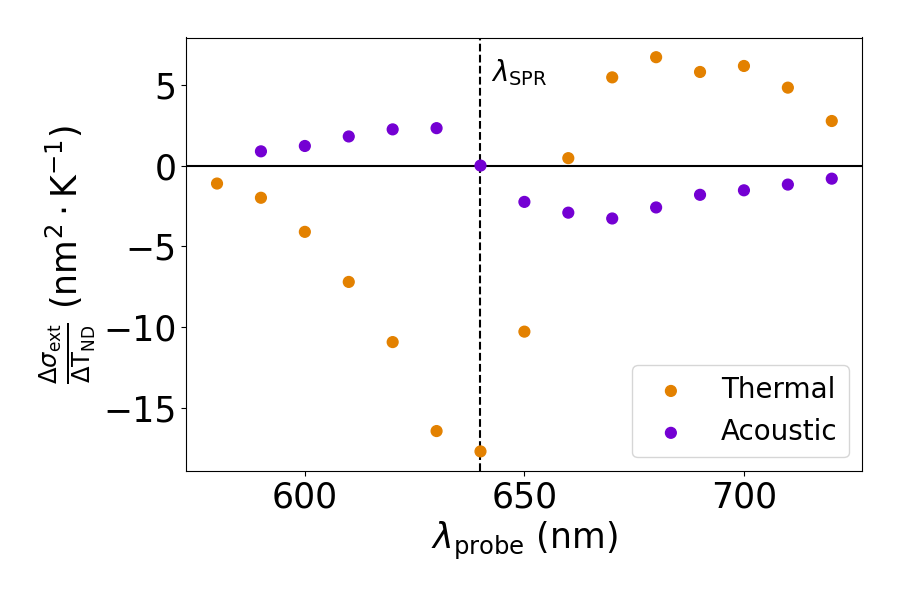

In [10]:
mpl.rcParams["font.size"] = 25

Data={}


Data['AR2.3 - NDd zone 3'] = {}


Data['AR2.3 - NDd zone 3']['lda_SPR'] = 640e-9


Data['AR2.3 - NDd zone 3']['color'] = '#488f31'


dir_root_2 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3'
dir_root_treated_data_2 = dir_root_2 + r'\Extinction variation calculation'
dir_root_exp_traces_2 = dir_root_2 + r'\PaP_study'
dir_root_simul_data_2 = dir_root_2 + r'\Simulation results'
fname_acoustic_2 = 'Treated_acoustic_data'
fname_thermic_2 = 'Treated_thermic_data'

Data['AR2.3 - NDd zone 3'] = {}
Data['AR2.3 - NDd zone 3']['color'] = '#488f31'
Data['AR2.3 - NDd zone 3']['lda_SPR'] = 640e-9
Data['AR2.3 - NDd zone 3']['acoustic'] = get_treated_data_dictionnary_dataset(dir_root_treated_data_2, fname_acoustic_2)
Data['AR2.3 - NDd zone 3']['thermic']  = get_treated_data_dictionnary_dataset(dir_root_treated_data_2, fname_thermic_2)
Data['AR2.3 - NDd zone 3']['All traces'] = get_all_raw_traces(dir_root_exp_traces_2)
Data['AR2.3 - NDd zone 3']['All traces'] = reorder_all_traces_dic(Data['AR2.3 - NDd zone 3']['All traces'])
Data['AR2.3 - NDd zone 3']['Simul_th'] = get_simulation_dsigma_thermic(dir_root_simul_data_2, 'd_sigma_simulation_thermic')


fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(Data['AR2.3 - NDd zone 3']['thermic']['lambda_probe'],Data['AR2.3 - NDd zone 3']['thermic']['Delta_sigma_th_normalized'],linestyle='', s=60, color = "#E38100", label='Thermal' )
#ax.errorbar(Data['AR2.3 - NDd zone 3']['thermic']['lambda_probe'],Data['AR2.3 - NDd zone 3']['thermic']['Delta_sigma_th_normalized'],linestyle='', yerr = np.abs(Data['AR2.3 - NDd zone 3']['thermic']['Delta_sigma_th_normalized_err']), color = "#ff0d0d" )

ax.scatter(Data['AR2.3 - NDd zone 3']['acoustic']['lambda_probe'],Data['AR2.3 - NDd zone 3']['acoustic']['Delta_sigma_ac_normalized'],linestyle='', s=60, color="#7400D3", label = 'Acoustic' )
#ax.errorbar(Data['AR2.3 - NDd zone 3']['acoustic']['lambda_probe'],Data['AR2.3 - NDd zone 3']['acoustic']['Delta_sigma_ac_normalized'],linestyle='', yerr = np.abs(Data['AR2.3 - NDd zone 3']['acoustic']['Delta_sigma_ac_normalized_err']), color = '#488f31' )

ax.axhline(0, color='black', zorder=0)
ax.axvline(Data['AR2.3 - NDd zone 3']['lda_SPR']*1e9, color = 'black', linestyle='--', zorder=0)

ax.set_xlabel(r'$\lambda_\mathrm{probe}$ (nm)')
ax.set_ylabel(r'$\frac{\Delta \sigma_\mathrm{ext}}{\Delta \mathrm{T}_\mathrm{ND}}$ (nm$^2 \cdot$K$^{-1}$)')
ax.text(0.45, 0.90, r'$\lambda_\mathrm{SPR}$', transform=ax.transAxes, fontsize=20)

#ax.annotate(text='', xy=(630,Data['AR2.3 - NDd zone 3']['thermic']['Delta_sigma_th_normalized'][5]+0.5), xytext=(630,0),arrowprops=dict(arrowstyle='<->', color="#E38100",linewidth=2.5))
#ax.text(590, 3, r'$\Delta \sigma_\mathrm{ext} / \Delta \mathrm{T_{ND}}$', color="#B97E00")

#ax.annotate(text='', xy=(630,-Data['AR2.3 - NDd zone 3']['acoustic']['Delta_sigma_ac_normalized'][4]), xytext=(630,0),arrowprops=dict(arrowstyle='<->', color="#B90900",linewidth=2.5))




fig.patch.set_facecolor( '#FF000000' )

#plt.xlim((550, 800))
plt.legend(fontsize=20, loc='lower right')
plt.tight_layout()

os.chdir(dir_save_data)

plt.savefig('Thermic_and_acoustic_sensitivity_study.svg')

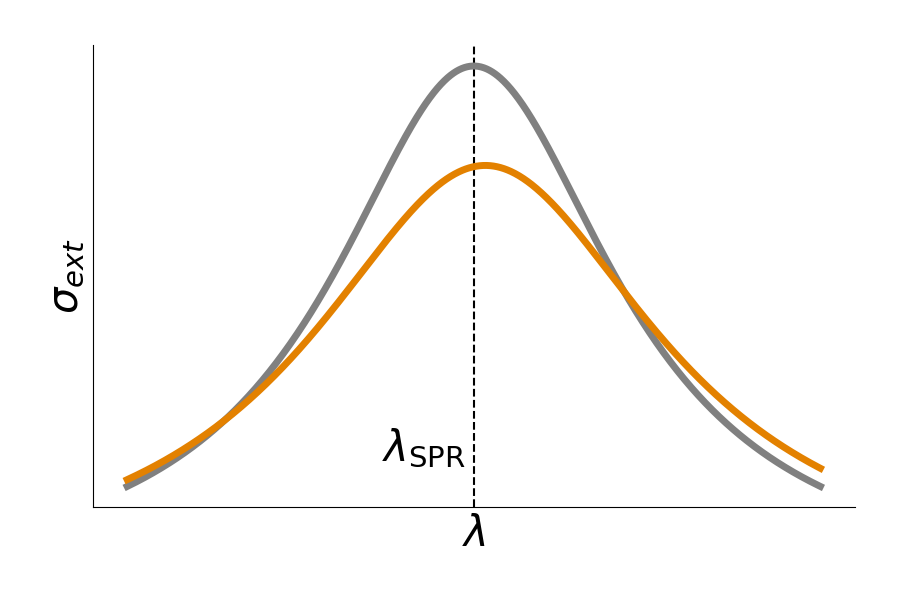

In [11]:
mpl.rcParams["font.size"] = 30
fig, ax = plt.subplots(figsize=(9,6))



Energy = np.linspace(1.7, 2.3, 1000)

x_probe = Energy[450]
delta_w = 0.07
tau = 800/3

delta_Ec_thermic = 0.01

#Lorentzian shape for the SPR
A = 1
E_c = 2
w = 0.3
y0=0


ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks
ax.set_xlabel(r'$\lambda$')
ax.set_ylabel(r'$\sigma_{ext}$')

ax.plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='grey', label ='SPR at equilibrium', linewidth=5)

ax.plot(Energy, Lorentz(Energy, E_c+ delta_Ec_thermic, w + delta_w, A, y0),color="#E38100", label = 'Thermal', linewidth=5)


#ax.annotate(text='', xy=(x_probe,Lorentz(x_probe, E_c, w, A, y0)), xytext=(x_probe,Lorentz(x_probe, E_c+ delta_Ec_thermic, w + delta_w, A, y0)),arrowprops=dict(arrowstyle='<->', color="#B97E00", linewidth=2.5))
#ax.text(x_probe-0.25, 3, r'$\Delta \sigma_\mathrm{ext}$', color="#B97E00")

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.axvline(E_c, color='black', linestyle='--',zorder=0)
ax.text(0.38, 0.1, r'$\lambda_\mathrm{SPR}$', transform=ax.transAxes)
fig.patch.set_facecolor( '#FF000000' )

#plt.legend(fontsize=15)
plt.tight_layout()


os.chdir(dir_save_data)

plt.savefig('Simple_scheme_thermic_variation.svg')

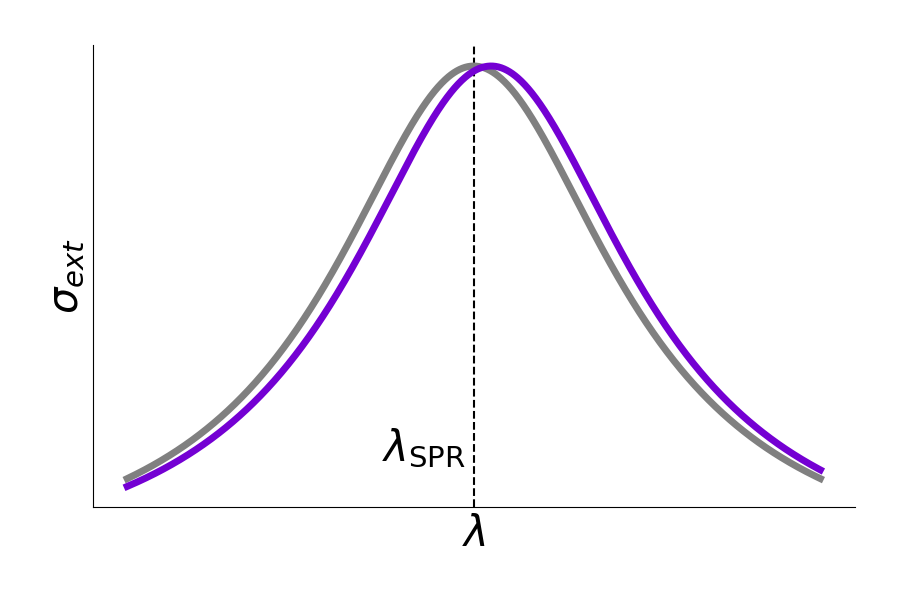

In [5]:
mpl.rcParams["font.size"] = 30
fig, ax = plt.subplots(figsize=(9,6))



Energy = np.linspace(1.7, 2.3, 1000)

x_probe = Energy[450]
delta_w = 0.07
tau = 800/3


delta_Ec_acoustic = 0.015
#Lorentzian shape for the SPR
A = 1
E_c = 2
w = 0.3
y0=0


ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks
ax.set_xlabel(r'$\lambda$')
ax.set_ylabel(r'$\sigma_{ext}$')

ax.plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='grey', label ='SPR at equilibrium', linewidth=5)

ax.plot(Energy, Lorentz(Energy, E_c+ delta_Ec_acoustic, w, A, y0),color="#7400D3", label = 'Acoustic', linewidth=5)


#ax.annotate(text='', xy=(x_probe,Lorentz(x_probe, E_c, w, A, y0)), xytext=(x_probe,Lorentz(x_probe, E_c+ delta_Ec_thermic, w + delta_w, A, y0)),arrowprops=dict(arrowstyle='<->', color="#B97E00", linewidth=2.5))
#ax.text(x_probe-0.25, 3, r'$\Delta \sigma_\mathrm{ext}$', color="#B97E00")

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# # make arrows
# ax.plot((1), (0), ls="", marker=">", ms=10, color="k",
#         transform=ax.get_yaxis_transform(), clip_on=False)
# ax.plot((0), (1), ls="", marker="^", ms=10, color="k",
#         transform=ax.get_xaxis_transform(), clip_on=False)



ax.axvline(E_c, color='black', linestyle='--',zorder=0)
ax.text(0.38, 0.1, r'$\lambda_\mathrm{SPR}$', transform=ax.transAxes)
fig.patch.set_facecolor( '#FF000000' )

#plt.legend(fontsize=15)
plt.tight_layout()


os.chdir(dir_save_data)

plt.savefig('Simple_scheme_acoustic_variation.svg')